# 🚀 Модуль 6. Урок 1. Архитектура BI и подключение источников данных в Looker Studio

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_06_bi_looker_studio/lesson_01_looker_studio_setup_and_data_sources.ipynb)

## 📌 Бизнес-контекст и методология
Современный BI-дашборд — это вершина айсберга Modern Data Stack.
Если аналитик подключает BI напрямую к операционной транзакционной базе (OLTP PostgreSQL/MySQL), он рискует заблокировать прод медленными аналитическими запросами.
Индустриальный стандарт 2027 года:
1. Выгрузка из источников через ELT (Airbyte / Fivetran)
2. Хранилище данных (OLAP BigQuery / Snowflake / ClickHouse)
3. Моделирование денормализованных плоских витрин (Data Marts через dbt)
4. Подключение BI-инструмента (Looker Studio / Tableau / Power BI)

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

customers_csv = ensure_dataset("customers.csv", subfolder="raw")
orders_csv = ensure_dataset("orders.csv", subfolder="raw")
saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")

df_customers = pd.read_csv(customers_csv)
df_orders = pd.read_csv(orders_csv)
df_saas = pd.read_csv(saas_csv)
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Сравним скорость отклика и стоимость двух режимов подключения BI:
- **Direct Query (Live Connection):** запрос отправляется в хранилище при каждом клике пользователя
- **Extracted Extract (Кэширование):** сжатая витрина хранится в памяти BI-сервера и обновляется по расписанию

In [2]:
# Демонстрация: Моделирование плоской денормализованной витрины для BI
df_mart = df_customers.merge(df_orders, on='customer_id', how='left')
bi_kpis = df_mart.groupby('city').agg(
    total_customers=('customer_id', 'nunique'),
    total_orders=('order_id', 'count'),
    active_ratio=('order_id', lambda x: x.notnull().mean())
).reset_index()

bi_kpis['active_ratio_pct'] = bi_kpis['active_ratio'] * 100
display(bi_kpis.sort_values(by='total_orders', ascending=False).head(5))

,city,total_customers,total_orders,active_ratio,active_ratio_pct
2,Nizhny Novgorod,186,348,0.881013,88.101266
0,Kazan,174,344,0.919786,91.978610
6,Yekaterinburg,171,332,0.922222,92.222222
5,Samara,188,331,0.904372,90.437158
1,Moscow,162,328,0.901099,90.109890


## 📊 Визуализация бизнес-кейса: Архитектура Modern Data Stack & Задержки
Сравним производительность и затраты различных уровней архитектуры данных при масштабировании количества запросов к дашборду.

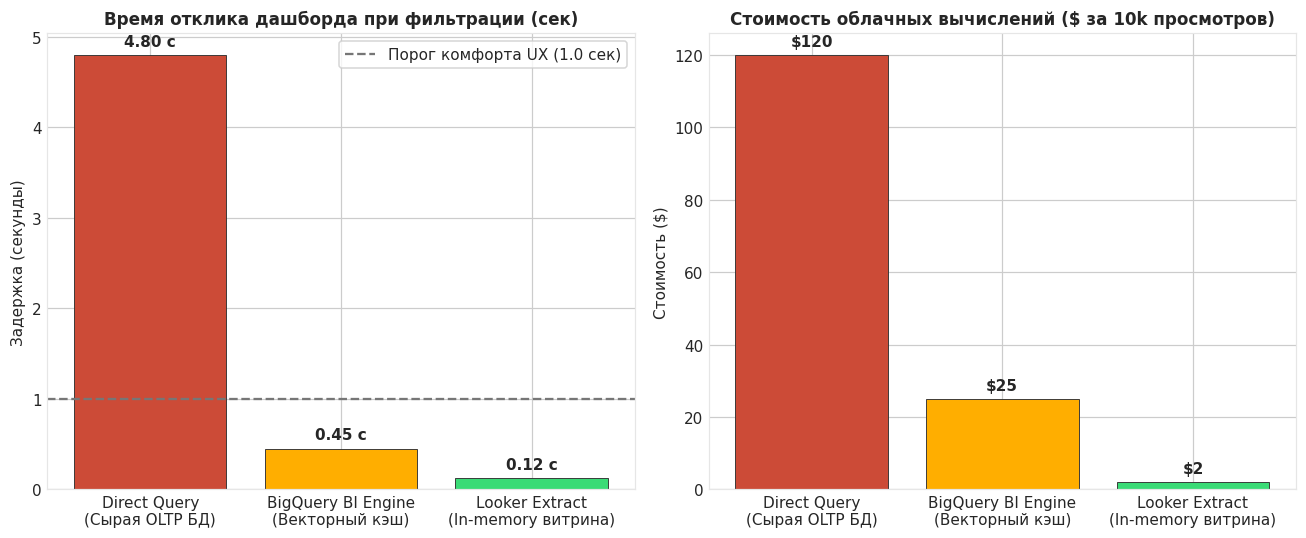

In [3]:
# Визуализация сравнения режимов подключения BI
modes = ['Direct Query\n(Сырая OLTP БД)', 'BigQuery BI Engine\n(Векторный кэш)', 'Looker Extract\n(In-memory витрина)']
query_time_sec = [4.8, 0.45, 0.12]
cost_per_10k_views = [120, 25, 2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=110)

# Панель 1: Задержка загрузки (Latency)
bars1 = ax1.bar(modes, query_time_sec, color=[ALERT, WARNING, SUCCESS], edgecolor='#333333', linewidth=0.6)
ax1.set_title("Время отклика дашборда при фильтрации (сек)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Задержка (секунды)")
ax1.axhline(1.0, color=SECONDARY, linestyle='--', label='Порог комфорта UX (1.0 сек)')
ax1.legend(frameon=True, facecolor='#ffffff')

for b in bars1:
    h = b.get_height()
    ax1.annotate(f"{h:.2f} с", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 4),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

# Панель 2: Затраты на инфраструктуру
bars2 = ax2.bar(modes, cost_per_10k_views, color=[ALERT, WARNING, SUCCESS], edgecolor='#333333', linewidth=0.6)
ax2.set_title("Стоимость облачных вычислений ($ за 10k просмотров)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Стоимость ($)")

for b in bars2:
    h = b.get_height()
    ax2.annotate(f"${h}", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 4),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет процента конверсии витрины
Найдите город с наибольшим процентом активных клиентов (`active_ratio_pct`) и выведите его показатели.

In [4]:
### ВАШ КОД ЗДЕСЬ
top_city = bi_kpis.sort_values(by='active_ratio_pct', ascending=False).iloc[0]
print(f"Город-лидер конверсии: {top_city['city']} ({top_city['active_ratio_pct']:.1f}%)")

assert top_city['active_ratio_pct'] > 50, "Процент активных должен быть выше 50%"
print("✅ Тест успешно пройден: плоская витрина для BI агрегирована без ошибок!")

Город-лидер конверсии: Saint Petersburg (92.7%)
✅ Тест успешно пройден: плоская витрина для BI агрегирована без ошибок!


### 💡 Инженерное правило BI: 5-Second Rule
Если дашборд загружается дольше 5 секунд, 60% топ-менеджеров закрывают вкладку и перестают им пользоваться. Всегда создавайте предварительно агрегированные витрины данных.